## Micro-Doppler Radar Classification
## Labeled 1.5-second micro-Doppler data and metadata collected using a stationary 24 GHz automotive radar.
## the notebook focuses on micro-doppler images. However, the metadata of the radar detections are also available and can be used as additional features.

## 1. Load the dataset
* The three pickle files are expected to be available in the current working directory.

In [1]:
import pickle
import numpy as np
from utils import *
with open("pedestrian.pkl", "rb") as f:
    pedestrian_data = pickle.load(f)
with open("car.pkl", "rb") as f:
    car_data = pickle.load(f)
with open("cyclist.pkl", "rb") as f:
    cyclist_data = pickle.load(f)

## 2. Extract micro-Doppler data and range metadata
* The final element of each record is treated as the micro-Doppler map. item[0][0] is treated as that record's range vector.

In [2]:
# Extract the micro-Doppler representation from each record.
car_doppler = [item[-1] for item in car_data]
cyclist_doppler = [item[-1] for item in cyclist_data]
pedestrian_doppler = [item[-1] for item in pedestrian_data]

# Extract the corresponding range metadata for each sample.
car_range = np.asarray([item[0][0] for item in car_data])
cyclist_range = np.asarray([item[0][0] for item in cyclist_data])
pedestrian_range = np.asarray([item[0][0] for item in pedestrian_data])

# Use the same number of samples from each class to balance the dataset.
datalen = np.min([
    len(car_doppler),
    len(cyclist_doppler),
    len(pedestrian_doppler),
])
print(datalen)

684


## 3. Range compensation
* The following applies the supplied correction, magnitude + 40 * log10(range), broadcasting each sample's range vector across its Doppler bins.

In [3]:
import numpy as np

car_doppler_compensated = car_doppler + 40 * np.log10(car_range)[:, None, :]
cyc_doppler_compensated = cyclist_doppler + 40 * np.log10(cyclist_range)[:, None, :]
ped_doppler_compensated = pedestrian_doppler + 40 * np.log10(pedestrian_range)[:, None, :]

# Replace non-finite values with the mean of the same sample.
# If a sample has no finite mean, use zero as the fallback.
def clean(x):
    x[~np.isfinite(x)] = np.nan
    means = np.nanmean(x, axis=(1, 2), keepdims=True)
    return np.where(np.isfinite(x), x, np.where(np.isfinite(means), means, 0))

car_doppler_compensated = clean(car_doppler_compensated.astype(float))
cyc_doppler_compensated = clean(cyc_doppler_compensated.astype(float))
ped_doppler_compensated = clean(ped_doppler_compensated.astype(float))

C:\Users\rajab\AppData\Local\Temp\ipykernel_16632\4080097859.py:3: RuntimeWarning: invalid value encountered in log10
  car_doppler_compensated = car_doppler + 40 * np.log10(car_range)[:, None, :]


## 4. Choose the input data
- option = 1: original data.
- option = 2: range-compensated data.

The code below keeps the original option selection.

In [4]:
# You can compare the effect of power compensation w.r.t. range on model performance.
option = 0

if option == 2:
    car_doppler_data = car_doppler_compensated
    pedestrian_doppler_data = ped_doppler_compensated
    cyclist_doppler_data = cyc_doppler_compensated
else:
    car_doppler_data = car_doppler
    pedestrian_doppler_data = pedestrian_doppler
    cyclist_doppler_data = cyclist_doppler

## 5. Create the balanced labeled dataset
* Labels are 0 = Pedestrian, 1 = Car, and 2 = Cyclist.

In [5]:
# Create the balanced dataset with labels.
training_data = []

# Add one class label to each selected sample.
training_data.extend([(sample, 0) for sample in pedestrian_doppler_data[:datalen]])
training_data.extend([(sample, 1) for sample in car_doppler_data[:datalen]])
training_data.extend([(sample, 2) for sample in cyclist_doppler_data[:datalen]])

# Separate the feature maps (X) and class labels (y).
import numpy as np

X = []
y = []

# Expected RD-map dimensions as used in the original code.
time_dim = 39
dopp_dim = 64  # Doppler bins

for features, label in training_data:
    # Store the original feature map and its class label.
    X.append(features)
    y.append(label)

y = np.asarray(y).reshape(-1)

## 6. Display an example micro-Doppler of a pedestrian

Text(0, 0.5, 'Doppler')

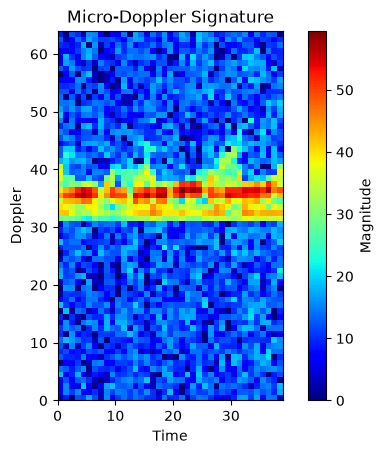

In [6]:
import matplotlib.pyplot as plt

plt.imshow(pedestrian_doppler[20],extent=[0,39,0,64],cmap='jet')
plt.colorbar(label="Magnitude")
plt.title("Micro-Doppler Signature")
plt.xlabel("Time")
plt.ylabel("Doppler")

## 7. PyTorch CNN
* The model uses two convolutional layers, max pooling, dropout, and fully connected layers.

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim

# Number of output classes.
num_classes = 3


class RadarModel(nn.Module):

    def __init__(self):
        super().__init__()

        # First convolutional layer.
        self.conv1 = nn.Conv2d(in_channels=1,out_channels=4,kernel_size=3,padding="same",)

        # Spatial downsampling.
        self.pool = nn.MaxPool2d(kernel_size=2,stride=2,)

        # Second convolutional layer.
        self.conv2 = nn.Conv2d(in_channels=4,out_channels=8,kernel_size=3,padding="same",)

        # Dropout for regularization.
        self.dropout = nn.Dropout(0.5)

        self.fc1 = nn.Linear(1152, 32)

        # Final classification layer.
        self.fc3 = nn.Linear(32, num_classes)

    def forward(self,image,):

        # Extract spatial features from the RD map.
        x = torch.relu(self.conv1(image))
        x = self.pool(x)

        x = torch.relu(self.conv2(x))
        x = self.pool(x)

        x = self.dropout(x)

        # Flatten the CNN feature maps.
        x = x.view(x.size(0), -1)

        # Fully connected classification layers.
        x = torch.relu(self.fc1(x))
        x = self.fc3(x)

        return x


# Create the model.
model = RadarModel()

print(model)

RadarModel(
  (conv1): Conv2d(1, 4, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(4, 8, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=1152, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=3, bias=True)
)


## 8. five-fold cross-validation
* the inialization is outside the main cell intentionally so that we can compare different models with the same cross-validation setup

In [8]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=20
)

# Generate fold assignments only once
fold_splits = list(skf.split(X, y))
# choose the model (cnn or cnn-lstm)
radar_model = 'cnn'

In [9]:
# ============================================================
# PyTorch CNN with 5-Fold Cross-Validation
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report


# ------------------------------------------------------------
# 1. Prepare the data
# ------------------------------------------------------------

# X: radar data
# y: labels
#
# Expected labels:
# 0 = pedestrian
# 1 = car
# 2 = cyclist

X_cv = np.asarray(X, dtype=np.float32)
y_cv = np.asarray(y, dtype=np.int64)

print("Data shape:", X_cv.shape)
print("Labels shape:", y_cv.shape)


# ------------------------------------------------------------
# 2. Configure cross-validation and training
# ------------------------------------------------------------

n_splits = 5
num_epochs = 80
batch_size = 32
learning_rate = 0.0005


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


# ------------------------------------------------------------
# 3. Store results for every fold
# ------------------------------------------------------------

fold_accuracies = []
fold_losses = []
fold_histories = []

all_y_true = []
all_y_pred = []


# ------------------------------------------------------------
# 4. Run five-fold cross-validation
# ------------------------------------------------------------

for fold, (train_idx, val_idx) in enumerate(fold_splits, start=1):
    print(f"\n{'=' * 20} Fold {fold}/{n_splits} {'=' * 20}")
    # Split data into training and validation sets
    X_train = X_cv[train_idx].copy()
    X_val = X_cv[val_idx].copy()

    y_train = y_cv[train_idx]
    y_val = y_cv[val_idx]


    # --------------------------------------------------------
    # 4a. Normalize using training data only
    # --------------------------------------------------------

    X_train, X_val = normalize_data(X_train, X_val, normalization="global")
    # 13 frames per sample each frame is 3 steps width
    if radar_model == 'cnn-lstm':
        X_train = np.asarray(X_train).reshape(-1, 13, 64, 3, 1)
        X_val = np.asarray(X_val).reshape(-1, 13, 64, 3, 1)


    # --------------------------------------------------------
    # 4b. Convert data to PyTorch tensors
    # --------------------------------------------------------

    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)

    y_train_tensor = torch.tensor(y_train, dtype=torch.long)

    y_val_tensor = torch.tensor(y_val, dtype=torch.long)


    # RadarModel uses Conv2d, so inputs must have shape:
    # (number_of_samples, channels, height, width)
    #
    # Add a channel dimension if the data is currently:
    # (number_of_samples, height, width)

    if X_train_tensor.ndim == 3:
        X_train_tensor = X_train_tensor.unsqueeze(1)
        X_val_tensor = X_val_tensor.unsqueeze(1)

    print("Training tensor shape:", X_train_tensor.shape)
    print("Validation tensor shape:", X_val_tensor.shape)

    set_seed(42 + fold)   # to ensure same data order each time (important for comparision)
    # --------------------------------------------------------
    # 4c. Create DataLoaders
    # --------------------------------------------------------

    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

    val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

    train_loader = DataLoader(train_dataset,batch_size=batch_size,shuffle=True)

    val_loader = DataLoader(val_dataset,batch_size=batch_size,shuffle=False)


    # --------------------------------------------------------
    # 4d. Initialize a fresh copy of the SAME  model
    # --------------------------------------------------------
    if radar_model == 'cnn':
        model = RadarModel().to(device)
    elif radar_model == 'cnn-lstm':
        model = MicroDopplerCNNLSTM(num_classes=3).to(device)
    else:
        model = RadarModel().to(device)

    print('Model is==========================', radar_model)
    
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(model.parameters(),lr=learning_rate)


    # --------------------------------------------------------
    # 4e. Train the model
    # --------------------------------------------------------

    history = {"train_loss": [],"val_loss": [],"val_accuracy": []}

    for epoch in range(num_epochs):

        # Training phase
        model.train()
        running_train_loss = 0.0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_train_loss += (loss.item() * inputs.size(0))

        train_loss = (running_train_loss / len(train_dataset))


        # Validation phase
        model.eval()

        running_val_loss = 0.0
        val_predictions = []
        val_targets = []

        with torch.no_grad():

            for inputs, labels in val_loader:

                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                running_val_loss += (loss.item() * inputs.size(0))

                predictions = torch.argmax(outputs, dim=1)

                val_predictions.extend(predictions.cpu().numpy())

                val_targets.extend(labels.cpu().numpy())

        val_loss = (running_val_loss / len(val_dataset))

        val_accuracy = accuracy_score(val_targets, val_predictions)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        #if (epoch + 1) % 10 == 0 or epoch == 0:
            #print(
                #f"Epoch [{epoch + 1:03d}/{num_epochs}] "
                #f"| Train Loss: {train_loss:.4f} "
                #f"| Val Loss: {val_loss:.4f} "
                #3f"| Val Accuracy: {val_accuracy:.4f}"
            #)


    # --------------------------------------------------------
    # 4f. Store final results for this fold
    # --------------------------------------------------------

    fold_accuracies.append(history["val_accuracy"][-1])
    fold_losses.append(history["val_loss"][-1])
    fold_histories.append(history)

    all_y_true.extend(val_targets)
    all_y_pred.extend(val_predictions)

    print(f"\nFold {fold} Results:")
    print(f"Validation Loss: {fold_losses[-1]:.4f}")
    print(f"Validation Accuracy: {fold_accuracies[-1]:.4f}")
    


# ------------------------------------------------------------
# 5. Summarize cross-validation results
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("5-Fold Cross-Validation Results")
print("=" * 50)

for fold in range(n_splits):
    print(f"Fold {fold + 1}: "f"Accuracy = {fold_accuracies[fold]:.4f}, "f"Loss = {fold_losses[fold]:.4f}")

mean_accuracy = np.mean(fold_accuracies)
std_accuracy = np.std(fold_accuracies)

mean_loss = np.mean(fold_losses)
std_loss = np.std(fold_losses)

print("\nMean Validation Accuracy: "
      f"{mean_accuracy:.4f} ± {std_accuracy:.4f}")

print("Mean Validation Loss: "
      f"{mean_loss:.4f} ± {std_loss:.4f}")


# ------------------------------------------------------------
# 6. Classification report across all validation folds
# ------------------------------------------------------------

print("\nClassification Report (all validation folds):")

print(
    classification_report(
        all_y_true,
        all_y_pred,
        labels=[0, 1, 2],
        target_names=["Pedestrian", "Car", "Cyclist"],
        zero_division=0
    )
)

Data shape: (2052, 64, 39)
Labels shape: (2052,)
Using device: cpu

==================== Fold 1/5 ====================
Training tensor shape: torch.Size([1641, 1, 64, 39])
Validation tensor shape: torch.Size([411, 1, 64, 39])
Model is========================== cnn

Fold 1 Results:
Validation Loss: 0.0461
Validation Accuracy: 0.9830

==================== Fold 2/5 ====================
Training tensor shape: torch.Size([1641, 1, 64, 39])
Validation tensor shape: torch.Size([411, 1, 64, 39])
Model is========================== cnn

Fold 2 Results:
Validation Loss: 0.0579
Validation Accuracy: 0.9732

==================== Fold 3/5 ====================
Training tensor shape: torch.Size([1642, 1, 64, 39])
Validation tensor shape: torch.Size([410, 1, 64, 39])
Model is========================== cnn

Fold 3 Results:
Validation Loss: 0.0597
Validation Accuracy: 0.9756

==================== Fold 4/5 ====================
Training tensor shape: torch.Size([1642, 1, 64, 39])
Validation tensor shape: to

## 9. Plot training and validation loss

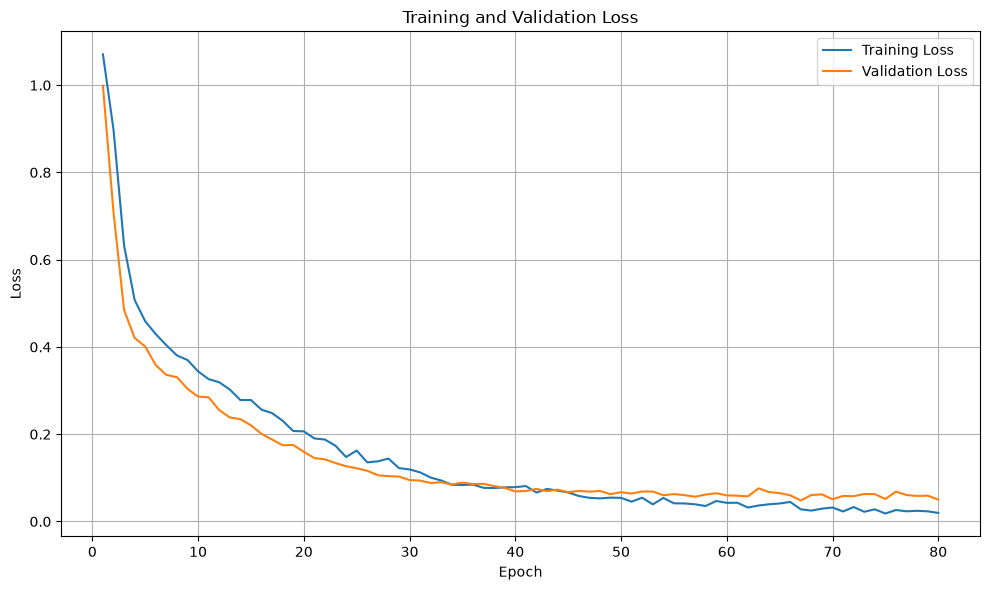

In [10]:
plt.figure(figsize=(10, 6))

plt.plot(range(1, num_epochs + 1),history["train_loss"],label="Training Loss",)

plt.plot(range(1, num_epochs + 1),history["val_loss"],label="Validation Loss",)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 11. Confusion matrix and class probabilities

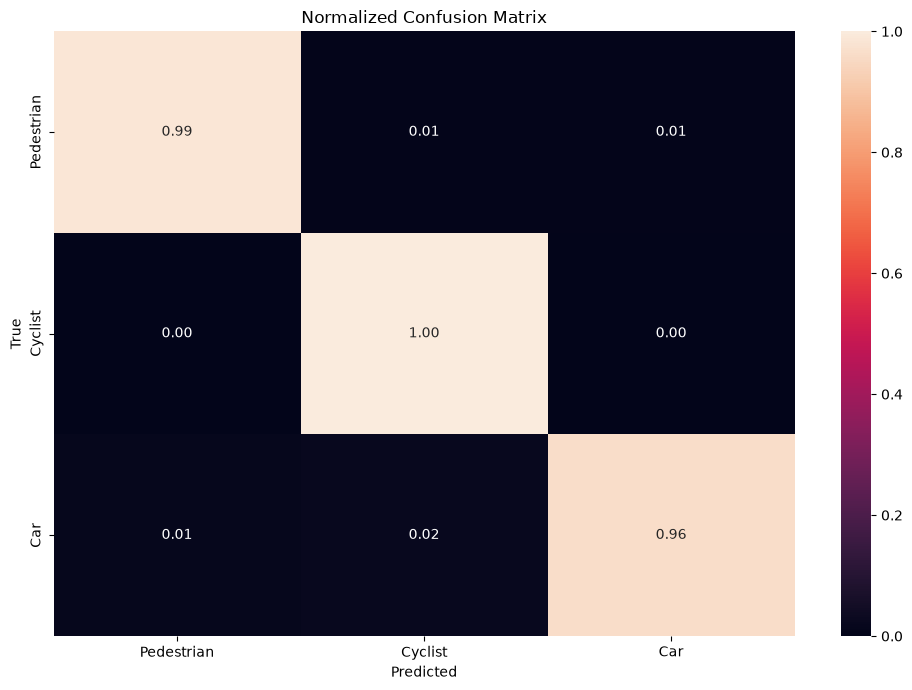

In [11]:
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Human-readable class names.
classes = {
    0: "Pedestrian",
    1: "Cyclist",
    2: "Car",
}

model.eval()

all_preds = []
all_labels = []
logs = []

with torch.no_grad():

    for batch in val_loader:

        (val_images,val_labels,) = batch

        # Model prediction.
        val_outputs = model(val_images,)

        # Convert logits to class probabilities.
        val_probabilities = torch.softmax(val_outputs,dim=1,)

        # Store probabilities and labels.
        logs.extend(val_probabilities.numpy())

        all_preds.extend( torch.argmax(val_probabilities,dim=1,).numpy())

        all_labels.extend(val_labels.numpy())

all_preds = np.asarray(all_preds)
all_labels = np.asarray(all_labels)
logs = np.asarray(logs)



# Calculate the confusion matrix.
cm = confusion_matrix(all_labels,all_preds,)

# Normalize each row so that each class is represented
# as a fraction of its true samples.
cmn = (cm.astype(float)/ cm.sum(axis=1)[:, np.newaxis])

plt.figure(figsize=(10, 7))

sns.heatmap(
    cmn,
    annot=True,
    fmt=".2f",
    xticklabels=list(classes.values()),
    yticklabels=list(classes.values()),
)

plt.ylabel("True")
plt.xlabel("Predicted")
plt.title("Normalized Confusion Matrix")

plt.tight_layout()
plt.show()

## 10. One-vs-rest ROC curves and AUC

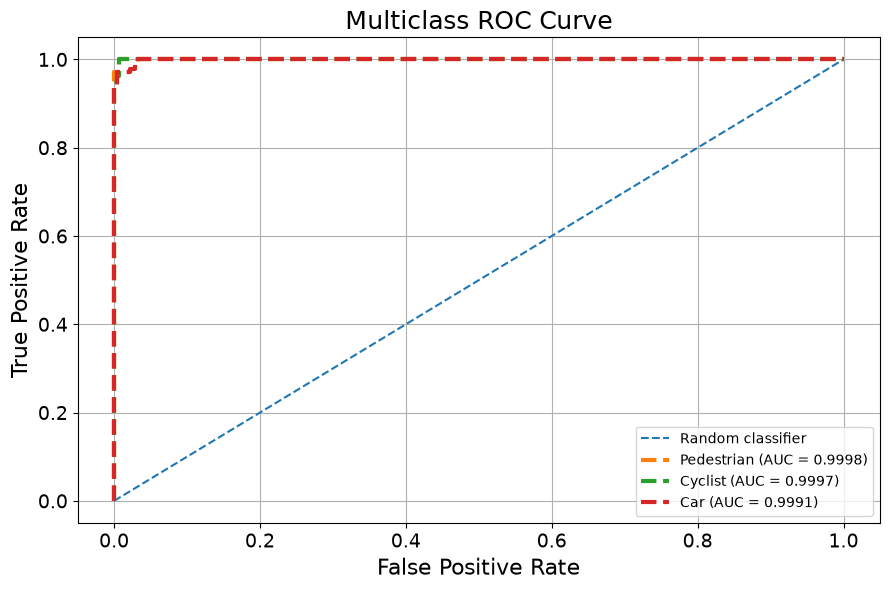

In [12]:
from sklearn.metrics import roc_curve, roc_auc_score

class_dict = {
    0: "Pedestrian",
    1: "Cyclist",
    2: "Car",
}

fpr = {}
tpr = {}
thresh = {}
roc_auc = {}

# Calculate a one-vs-rest ROC curve for every class.
for i in range(num_classes):

    binary_labels = (all_labels == i ).astype(int)

    fpr[i], tpr[i], thresh[i] = roc_curve(binary_labels,logs[:, i],)

    roc_auc[i] = roc_auc_score(binary_labels,logs[:, i],)

# Plot all one-vs-rest ROC curves.

plt.figure(figsize=(9, 6))

# Random-classifier reference line.
plt.plot([0, 1],[0, 1],linestyle="--",label="Random classifier",)

for i in range(num_classes):

    class_name = class_dict.get(i,f"Class {i}",)

    plt.plot(fpr[i],tpr[i],linestyle="--",linewidth=3,label=(f"{class_name} "
            f"(AUC = {roc_auc[i]:.4f})"
        ),
    )

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlabel("False Positive Rate",fontsize=16,)

plt.ylabel("True Positive Rate",fontsize=16,)

plt.title("Multiclass ROC Curve",fontsize=18,)

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()

## Time-distributed CNN Model

In [51]:
import torch
import torch.nn as nn
import torch.optim as optim


class MicroDopplerCNNLSTM(nn.Module):
    def __init__(self, num_classes=4):
        super(MicroDopplerCNNLSTM, self).__init__()

        # Keras input: (batch, 13, 64, 3, 1)
        # PyTorch input: (batch, 13, 1, 64, 3)

        # TimeDistributed(Conv2D(4, (4, 4), padding="same"))
        self.conv2d = nn.Conv2d(in_channels=1,out_channels=4,kernel_size=(4, 4),padding="same")

        self.relu = nn.ReLU()

        # TimeDistributed(MaxPooling2D(pool_size=(2, 2)))
        self.pool = nn.MaxPool2d(kernel_size=(2, 2))

        self.dropout1 = nn.Dropout(0.3)

        # After Conv2D and pooling:
        # (4, 64, 3) -> (4, 32, 1)
        # Flattened features = 4 * 32 * 1 = 128
        self.flatten = nn.Flatten(start_dim=2)

        # LSTM(50, activation="relu")
        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=50,
            batch_first=True
        )

        self.dropout2 = nn.Dropout(0.3)

        # Dense(4, activation="softmax")
        self.fc = nn.Linear(50, num_classes)

    def forward(self, x):
        # x: (batch, time, height, width, channels)
        # Expected input: (B, 13, 64, 3, 1)

        batch_size, time_steps, height, width, channels = x.shape

        # Convert to PyTorch image format:
        # (B, T, H, W, C) -> (B, T, C, H, W)
        x = x.permute(0, 1, 4, 2, 3)

        # Apply Conv2D independently to every time step.
        x = x.reshape(batch_size * time_steps,channels,height,width)
        x = self.relu(self.conv2d(x))
        x = self.pool(x)

        # Dropout and flatten each frame.
        x = self.dropout1(x)
        x = self.flatten(x)

        # (B*T, 128) -> (B, T, 128)
        x = x.reshape(batch_size, time_steps, -1)

        # LSTM returns output for every time step.
        # We use the last hidden state, as Keras LSTM does by default.
        _, (hidden, _) = self.lstm(x)
        x = hidden[-1]  # (B, 50)

        x = self.dropout2(x)
        x = self.fc(x)  # Raw logits (B, 4)

        return x


# Initialize model.
model = MicroDopplerCNNLSTM(num_classes=3)

# Adam optimizer, learning rate = 0.001.
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Equivalent to sparse_categorical_crossentropy.
# PyTorch CrossEntropyLoss expects raw logits.
criterion = nn.CrossEntropyLoss()

